@author: Octavio Gutiérrez de Código Máquina 

URL del canal: https://www.youtube.com/CodigoMaquina 

URL del video: https://youtu.be/wm9ONSvOoO8

<h1 style="color:purple">Técnica de Bootstrapping</h1> 
<h2 style="color:blue">Generación Sintética de una Población</h2> 

## La idea, en palabras sencillas
Queremos calcular un promedio, pero no siempre podemos medir a todas las personas. Entonces tomamos un grupo pequeño y usamos sus datos para tener una idea del grupo completo.

### Ejemplo de la vida diaria: esperar en una fila
Imagina que anotas cuánto esperan 5 clientes en una cafetería: **2, 3, 4, 6 y 10 minutos**. El promedio de esos 5 tiempos es **5 minutos**. Pero, ¿será también el promedio para todos los clientes? No lo sabemos con solo 5 personas.

Con bootstrapping volvemos a elegir 5 tiempos de esa misma lista, permitiendo repetir un tiempo. Por ejemplo, una nueva lista podría ser **2, 2, 2, 6 y 10**; otra podría ser **3, 3, 4, 4 y 10**. Calculamos el promedio de cada lista y repetimos muchas veces. Así vemos cuánto cambia el promedio cuando usamos grupos distintos.

En esta libreta hacemos lo mismo con **calificaciones inventadas por la computadora**: hay 100.000 en el grupo completo, tomamos 100 y creamos 1.000 grupos nuevos de esos 100 datos.

Al final, el rango de promedios más comunes nos da una idea de cuál podría ser el promedio de todo el grupo. No es una respuesta segura: es una estimación con un margen de duda.

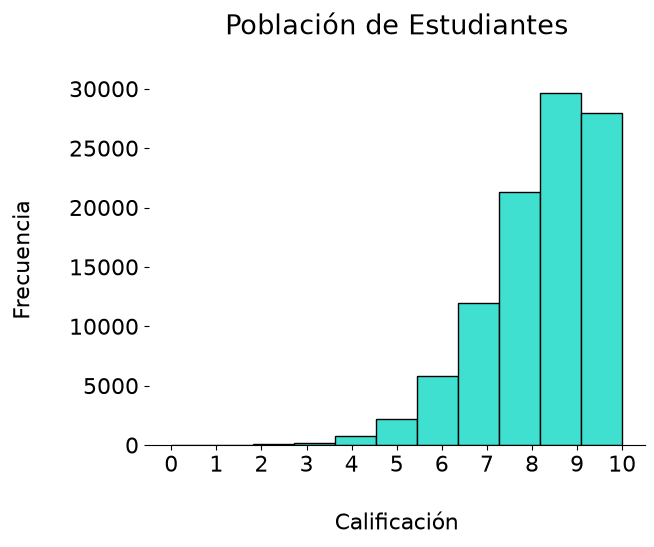

In [1]:
from scipy import stats  # Herramienta que usaremos para crear calificaciones.
import matplotlib.pyplot as plt  # Herramienta para dibujar gráficos; la llamaremos plt.
import numpy as np  # Herramienta para trabajar con muchos números; la llamaremos np.

np.random.seed(0)  # Hace que los sorteos de números den el mismo resultado cada vez.

# Estas líneas cambian solo la apariencia de los gráficos.
plt.rcParams["font.size"] = 16  # Usa letras un poco más grandes.
plt.rcParams["axes.spines.top"] = False  # Quita el borde de arriba.
plt.rcParams["axes.spines.right"] = False  # Quita el borde de la derecha.
plt.rcParams["axes.spines.left"] = False  # Quita el borde de la izquierda.

# Esta función crea una lista de calificaciones parecidas a las de un grupo real.
def datos_sesgados(sesgo, cantidad, maximo):  # Le damos cuánto inclinar los datos, cuántos crear y la nota más alta.
    aleatorios = stats.skewnorm.rvs(sesgo,  # Crea números al azar; sesgo negativo da más notas altas y pocas bajas.
                                    size=cantidad,  # Dice cuántos números crear.
                                    random_state=0)  # Repite los mismos números cada vez.
    aleatorios = aleatorios + abs(aleatorios.min())  # Mueve los números para que ninguno sea negativo.
    aleatorios = np.round(aleatorios, 2) / aleatorios.max() * maximo  # Ajusta los números para que el mayor llegue a maximo.
    return np.round(aleatorios, 1)  # Entrega las notas redondeadas a un decimal.

califs = datos_sesgados(-25.0, 100000, 10)  # Crea 100.000 calificaciones de hasta 10.

# El histograma cuenta cuántas notas hay en cada rango.
plt.hist(califs, bins=11, color="turquoise", edgecolor="black")  # bins=11 pide 11 barras.
plt.title("Población de Estudiantes\n")  # Escribe el título.
plt.xticks(range(0, 11))  # Marca los números del 0 al 10 abajo.
plt.xlabel("\nCalificación")  # Dice qué significan los números de abajo.
plt.ylabel("Frecuencia\n")  # Dice que la altura de cada barra cuenta notas.
plt.show()  # Muestra el gráfico.

<h2 style="color:purple">Extracción de una Muestra (Principal)</h2>

Tomamos **100 calificaciones** de las 100.000. Es como sacar 100 nombres al azar de una lista grande. El histograma de arriba muestra cuántas calificaciones hay en cada rango; aquí hay muchas notas altas y menos bajas. En un estudio real, hay que elegir personas de forma justa para que la muestra represente al grupo.

In [ ]:
tamano_muestra = 100  # Queremos que el grupo pequeño tenga 100 notas.
muestra_principal = np.random.choice(califs,  # Elige notas al azar de la población.
                                     tamano_muestra,  # Elige 100 notas.
                                     replace=False)  # No repite una nota en este primer sorteo.
muestra_principal  # Muestra las 100 notas elegidas.

<h2 style="color:purple">1000 muestras con Bootstrapping</h2>

Ahora hacemos **1.000 grupos nuevos** usando solo las 100 calificaciones de `muestra_principal`. Cada grupo tiene 100 valores. Como dejamos que un valor se repita, puede salir varias veces en un mismo grupo; eso es parte de este método.

In [ ]:
muestras = np.array([])  # Empieza una lista vacía para guardar los grupos nuevos.
num_muestras = 1000  # Vamos a crear 1.000 grupos nuevos.
for m in range(num_muestras):  # Repite lo que está adentro 1.000 veces.
    muestras = np.append(muestras,  # Guarda el nuevo grupo junto a los anteriores.
                         np.random.choice(muestra_principal,  # Elige de las 100 notas originales.
                                          tamano_muestra,  # Cada grupo nuevo tiene 100 notas.
                                          replace=True))  # Permite que una misma nota salga más de una vez.
muestras = muestras.reshape(-1, tamano_muestra)  # Ordena todo en 1.000 filas de 100 notas.
muestras.shape, muestras  # Muestra el tamaño y los valores de los grupos.

<h1 style="color:purple">Distribución Muestral de la Media</h1>

Calculamos el promedio de cada uno de los 1.000 grupos. En el histograma, cada barra cuenta cuántos grupos tuvieron un promedio parecido. Si las barras están muy juntas, los promedios cambian poco; si están muy extendidas, hay más variación.

In [ ]:
plt.hist(muestras.mean(axis=1), bins=100, color="turquoise")  # Saca el promedio de cada fila (cada grupo nuevo).
plt.xlabel("\nCalificaciones promedio de las muestras")  # Abajo vemos los promedios, no las notas individuales.
plt.ylabel("Frecuencia\n")  # A un lado vemos cuántos grupos dieron promedios parecidos.
plt.show()  # Muestra el gráfico.

<h1 style="color:purple">Cálculo del Intervalo de Confianza</h1>

Las dos líneas rosadas marcan el principio y el final del rango de promedios que usamos como **intervalo del 95%**. La línea dorada es el promedio de nuestros 100 datos. La negra es el promedio real de las 100.000 calificaciones; podemos verla porque estos datos fueron inventados por la computadora.

En un caso real no conocemos la línea negra. El intervalo nos da un rango razonable en lugar de un solo número. El 95% quiere decir que, si repitiéramos este proceso muchas veces, la mayoría de los intervalos incluirían el promedio real.

In [ ]:
# Busca los límites que dejan la mayoría de los promedios dentro del rango.
intervalo_confianza = np.quantile(muestras.mean(axis=1),  # Mira los promedios de los grupos nuevos.
                                  [0.025, 0.975])  # Guarda el límite de abajo y el de arriba.

# Prepara puntos para dibujar el rango en el gráfico.
x = np.linspace(intervalo_confianza[0], intervalo_confianza[1], 100)  # Crea 100 puntos entre los dos límites.
y = [10] * x.size  # Pone todos los puntos a la misma altura del dibujo.

# Dibuja el rango de puntos rosados.
plt.scatter(x, y, color="deeppink", s=100)  # Dibuja puntos; s cambia su tamaño.

# Dibuja una línea rosada en el límite de abajo.
plt.axvline(intervalo_confianza[0],  # Dónde poner la línea.
            label="IC: Límite inferior",  # Nombre que veremos en la leyenda.
            color="deeppink",  # Color de la línea.
            lw=4,  # Qué tan gruesa es la línea.
            linestyle="--")  # -- dibuja una línea cortada.

# Dibuja una línea rosada en el límite de arriba.
plt.axvline(intervalo_confianza[1],  # Dónde poner la línea.
            label="IC: Límite superior",  # Nombre que veremos en la leyenda.
            color="deeppink",  # Usa el mismo color que el otro límite.
            lw=4,  # Qué tan gruesa es la línea.
            linestyle="--")  # Línea cortada.

# Marca el promedio de las 100.000 notas que inventó la computadora.
plt.axvline(califs.mean(),  # Calcula ese promedio.
            label="Media poblacional",  # Nombre que aparece en la leyenda.
            color="black",  # Dibuja la línea negra.
            lw=10,  # Hace la línea gruesa.
            linestyle=":")  # : dibuja una línea de puntos.

# Marca el promedio de las 100 notas que elegimos primero.
plt.axvline(muestra_principal.mean(),  # Calcula ese promedio.
            label="Media de muestra principal",  # Nombre para la leyenda.
            color="gold",  # Dibuja la línea dorada.
            lw=10)  # Hace la línea gruesa.

# Dibuja las barras de los promedios de los 1.000 grupos.
plt.hist(muestras.mean(axis=1),  # Calcula un promedio por cada grupo.
         bins=100,  # Divide los promedios en 100 rangos.
         alpha=0.5,  # Hace las barras transparentes para ver las líneas.
         color="turquoise")  # Color de las barras.

plt.title("Intervalo de Confianza al 95%\n")  # Escribe el título del gráfico.
plt.xlabel("\nCalificaciones promedio de las muestras")  # Abajo están los promedios.
plt.ylabel("Frecuencia\n")  # A un lado contamos cuántos grupos hay en cada barra.
plt.legend(bbox_to_anchor=(1, 0.5))  # Muestra qué significa cada color, a la derecha.
plt.show()  # Muestra el gráfico final.